<a href="https://colab.research.google.com/github/Sonickers/uni-vending-machine/blob/master/titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pobranie danych

In [ ]:
import kagglehub
import pandas as pd
import os

# Pobranie najnowszej wersji zbioru Titanic
path = kagglehub.dataset_download("yasserh/titanic-dataset")
print("Ścieżka do plików:", path)

# Utworzenie pełnej ścieżki i wczytanie danych do obiektu DataFrame (df)
file_path = os.path.join(path, 'Titanic-Dataset.csv')
df = pd.read_csv(file_path)

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Ścieżka do plików: /kaggle/input/titanic-dataset


# Eksploracja i zrozumienie danych

In [ ]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [ ]:
null_counts = df.isnull().sum()
print("Liczba brakujących wartości w poszczególnych kolumnach:")
print(null_counts[null_counts > 0])

Liczba brakujących wartości w poszczególnych kolumnach:
Age         177
Cabin       687
Embarked      2
dtype: int64


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
886,False
887,False
888,False
889,False


In [ ]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
print(df.duplicated().sum())

0


# Przygotowanie danych (preprocessing)

In [ ]:
from sklearn.linear_model import LinearRegression
import numpy as np

# 1. Port zaokrętowania (Embarked)
# Uzupełniamy najczęściej występującą wartością
most_freq_port = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(most_freq_port)

# 2. Kabina (Cabin)
# Tworzymy kolumnę binarną: 1 jeśli miał kabinę, 0 jeśli nie [cite: 51]
df['Has_Cabin'] = df['Cabin'].notnull().astype(int)

# 3. Wiek (Age) - Predykcja regresją
# Wybieramy 4 kolumny do regresji
features_for_age = ['Pclass', 'SibSp', 'Parch', 'Fare']

# Sprawdzamy braki w Age
if df['Age'].isnull().any():
    train_age = df[df['Age'].notnull()]
    test_age = df[df['Age'].isnull()]

    lr = LinearRegression()
    lr.fit(train_age[features_for_age], train_age['Age'])

    predicted_ages = lr.predict(test_age[features_for_age])

    # Wiek nie może być ujemny
    predicted_ages = np.maximum(predicted_ages, 0)

    df.loc[df['Age'].isnull(), 'Age'] = predicted_ages
    print("Braki w kolumnie Age zostały uzupełnione regresją.")
else:
    print("Brak brakujących wartości w kolumnie Age.")

# Weryfikacja braków
print("\nAktualna liczba braków:")
print(df[['Age', 'Embarked', 'Has_Cabin']].isnull().sum())

Brak brakujących wartości w kolumnie Age.

Aktualna liczba braków:
Age          0
Embarked     0
Has_Cabin    0
dtype: int64


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Has_Cabin
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,0.647587,29.333328,0.523008,0.381594,32.204208,0.228956
std,257.353842,0.486592,0.836071,0.477990,13.502964,1.102743,0.806057,49.693429,0.420397
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,0.000000,22.000000,0.000000,0.000000,7.910400,0.000000
50%,446.000000,0.000000,3.000000,1.000000,27.539522,0.000000,0.000000,14.454200,0.000000
75%,668.500000,1.000000,3.000000,1.000000,36.000000,1.000000,0.000000,31.000000,0.000000
max,891.000000,1.000000,3.000000,1.000000,80.000000,8.000000,6.000000,512.329200,1.000000


In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd # Make sure pandas is imported

# 1. Kodowanie płci (Sex) - LabelEncoder (zamiana na 0 i 1)
# Check if 'Sex' column is still object type before encoding
if df['Sex'].dtype == 'object':
    le = LabelEncoder()
    df['Sex'] = le.fit_transform(df['Sex'])
    print("Kolumna 'Sex' została zakodowana.")
else:
    print("Kolumna 'Sex' jest już zakodowana.")

# 2. Kodowanie portu (Embarked) - One-Hot Encoding
# drop_first=True usuwa jedną kolumnę, by uniknąć korelacji
if 'Embarked' in df.columns:
    df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)
    print("Kolumna 'Embarked' została zakodowana One-Hot Encoding.")
else:
    print("Kolumna 'Embarked' nie istnieje w DataFrame (prawdopodobnie została już zakodowana).")

# Sprawdźmy jak wyglądają teraz kolumny
print("\nNowe kolumny po kodowaniu:")
print(df.columns.tolist())

# Podgląd przetworzonych danych
df.head()

Kolumna 'Sex' jest już zakodowana.
Kolumna 'Embarked' nie istnieje w DataFrame (prawdopodobnie została już zakodowana).

Nowe kolumny po kodowaniu:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Has_Cabin', 'Embarked_Q', 'Embarked_S']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Has_Cabin,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,NaN,0,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,1,False,False
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,NaN,0,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,1,False,True
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,NaN,0,False,True


# k-najbliższych sąsiadów (KNN)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score

# 1. Wybór cech (X) i celu (y) zgodnie z instrukcją [cite: 57]
X = df[['Sex', 'Pclass', 'SibSp', 'Parch', 'Fare', 'Age', 'Embarked_Q', 'Embarked_S', 'Has_Cabin']]
y = df['Survived']

# 2. Podział na zbiór uczący (80%) i testujący (20%) [cite: 58]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Skalowanie danych - KLUCZOWE dla KNN, bo opiera się na odległości
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Tuning parametru k - sprawdzamy różne liczby sąsiadów [cite: 63]
print("--- Wyniki tuningu parametru k ---")
best_k = 0
best_f1 = 0

for k in [1, 5, 7, 13]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    y_pred = knn.predict(X_test_scaled)
    score = f1_score(y_test, y_pred)

    print(f"Dla k = {k}, wynik: {score:.4f}")

    if score > best_f1:
        best_f1 = score
        best_k = k

print("-" * 30)
print(f"Najlepszy model to k = {best_k} z wynikiem F1 = {best_f1:.4f}")

--- Wyniki tuningu parametru k ---
Dla k = 1, wynik: 0.6986
Dla k = 5, wynik: 0.7703
Dla k = 7, wynik: 0.7815
Dla k = 13, wynik: 0.7671
------------------------------
Najlepszy model to k = 7 z wynikiem F1 = 0.7815


Dokładność (Accuracy): 0.8156

--- Raport klasyfikacji ---
              precision    recall  f1-score   support

  Zginął (0)       0.85      0.83      0.84       105
 Przeżył (1)       0.77      0.80      0.78        74

    accuracy                           0.82       179
   macro avg       0.81      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



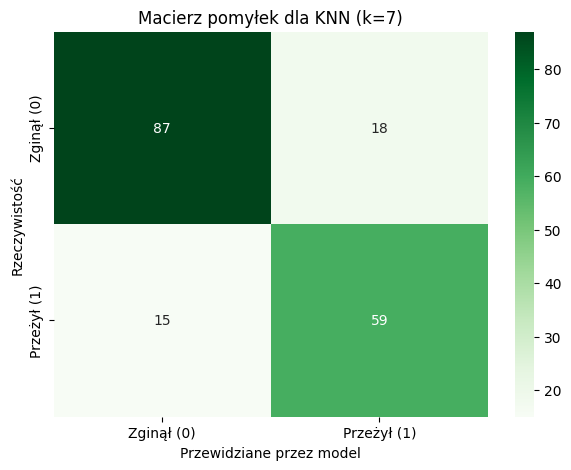

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Trenujemy najlepszy model (k=7 wyszło u Ciebie najlepiej)
knn_final = KNeighborsClassifier(n_neighbors=7)
knn_final.fit(X_train_scaled, y_train)
y_pred_final = knn_final.predict(X_test_scaled)

# 2. Obliczamy Dokładność (Accuracy)
accuracy = accuracy_score(y_test, y_pred_final)
print(f"Dokładność (Accuracy): {accuracy:.4f}")

# 3. Wyświetlamy Raport klasyfikacji
print("\n--- Raport klasyfikacji ---")
print(classification_report(y_test, y_pred_final, target_names=['Zginął (0)', 'Przeżył (1)']))

# 4. Tworzymy Macierz pomyłek
cm = confusion_matrix(y_test, y_pred_final)

# Wizualizacja macierzy
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Zginął (0)', 'Przeżył (1)'],
            yticklabels=['Zginął (0)', 'Przeżył (1)'])
plt.xlabel('Przewidziane przez model')
plt.ylabel('Rzeczywistość')
plt.title('Macierz pomyłek dla KNN (k=7)')
plt.show()

# LogisticRegression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report

# 1. Inicjalizacja i trenowanie modelu
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

# 2. Predykcja na zbiorze testowym
y_pred_log = log_reg.predict(X_test_scaled)

# 3. Obliczenie wyniku F1-score
f1_log = f1_score(y_test, y_pred_log)

print(f"Wynik dla Regresji Logistycznej: {f1_log:.4f}")

Wynik dla Regresji Logistycznej: 0.7778


# Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# 1. Inicjalizacja i trenowanie modelu
# n_estimators=100 oznacza, że budujemy las ze 100 drzew
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 2. Predykcja
y_pred_rf = rf_model.predict(X_test)

# 3. Ewaluacja
f1_rf = f1_score(y_test, y_pred_rf)
print(f"Wynik dla Random Forest: {f1_rf:.4f}")

Wynik dla Random Forest: 0.7778


# SVC (Support Vector Classifier) i Grid Search

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# 1. Definicja parametrów do sprawdzenia
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf'] # jądro radialne, najlepsze dla nieliniowych danych
}

# 2. Inicjalizacja Grid Search z modelem SVC
grid = GridSearchCV(SVC(), param_grid, refit=True, verbose=0, cv=5)
grid.fit(X_train_scaled, y_train)

# 3. Wybór najlepszego modelu i predykcja
best_svc = grid.best_estimator_
y_pred_svc = best_svc.predict(X_test_scaled)

# 4. Ewaluacja
f1_svc = f1_score(y_test, y_pred_svc)
print(f"Najlepsze parametry SVC: {grid.best_params_}")
print(f"Wynik dla SVC: {f1_svc:.4f}")

Najlepsze parametry SVC: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
Wynik dla SVC: 0.7626


# XGBoost (XGBClassifier)

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import f1_score

# Inicjalizacja modelu XGBoost
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
# Trenujemy na danych NIEskalowanych (X_train)
xgb_model.fit(X_train, y_train)

# Predykcja i wynik
y_pred_xgb = xgb_model.predict(X_test)
f1_xgb = f1_score(y_test, y_pred_xgb)
print(f"Wynik dla XGBoost: {f1_xgb:.4f}")

Wynik dla XGBoost: 0.7917
